In [1]:
# Install Java
!apt-get install openjdk-8-jdk-headless -qq > /dev/null

# Download and extract Apache Spark
!wget -q https://archive.apache.org/dist/spark/spark-3.0.3/spark-3.0.3-bin-hadoop3.2.tgz
!tar xf spark-3.0.3-bin-hadoop3.2.tgz

# Set environment variables
import os
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-8-openjdk-amd64"
os.environ["SPARK_HOME"] = "/content/spark-3.0.3-bin-hadoop3.2"

In [2]:
# Install findspark
!pip install -q findspark

# Initialize Spark in your notebook
import findspark
findspark.init()

In [3]:
from pyspark.sql import SparkSession
spark = SparkSession.builder\
        .master("local")\
        .appName("Colab")\
        .config('spark.ui.port', '4050')\
        .getOrCreate()

In [4]:
#Read Sales data file
df_1 = spark.read.csv("Dataset1.csv", header = "true", inferSchema = "true")
df_1.show(5)

+------+--------------+----------+----------+---------+---------+--------------+-----------+-------------+-----------+--------------+------------+--------------+-----------+-------+-----------------+---------------+---------------+------------+--------------------+--------------------+--------+--------+--------+--------+
|Row ID|      Order ID|Order Date|Order_Week|Ship Date|Ship_Week|     Ship Mode|Customer ID|Customer Name|    Segment|Country/Region|        City|State/Province|Postal Code| Region| Regional Manager|     Product ID|       Category|Sub-Category|        Product Name|               Sales|Quantity|Discount|  Profit|Returned|
+------+--------------+----------+----------+---------+---------+--------------+-----------+-------------+-----------+--------------+------------+--------------+-----------+-------+-----------------+---------------+---------------+------------+--------------------+--------------------+--------+--------+--------+--------+
|     1|US-2019-103800|  1/3/20

In [5]:
#Read Target Sales data file
df_2 = spark.read.csv("Dataset2.csv", header = "true", inferSchema = "true")
df_2.show(5)

+---------------+----------+-----------+------------+
|       Category|Order Date|    Segment|Sales Target|
+---------------+----------+-----------+------------+
|Office Supplies|  1/3/2019|   Consumer|          15|
|Office Supplies|  1/4/2019|Home Office|         300|
|Office Supplies|  1/5/2019|   Consumer|          21|
|      Furniture|  1/6/2019|Home Office|        2316|
|Office Supplies|  1/6/2019|   Consumer|          17|
+---------------+----------+-----------+------------+
only showing top 5 rows



In [6]:
# Checking the schema.
df_1.printSchema()

root
 |-- Row ID: integer (nullable = true)
 |-- Order ID: string (nullable = true)
 |-- Order Date: string (nullable = true)
 |-- Order_Week: string (nullable = true)
 |-- Ship Date: string (nullable = true)
 |-- Ship_Week: string (nullable = true)
 |-- Ship Mode: string (nullable = true)
 |-- Customer ID: string (nullable = true)
 |-- Customer Name: string (nullable = true)
 |-- Segment: string (nullable = true)
 |-- Country/Region: string (nullable = true)
 |-- City: string (nullable = true)
 |-- State/Province: string (nullable = true)
 |-- Postal Code: string (nullable = true)
 |-- Region: string (nullable = true)
 |-- Regional Manager: string (nullable = true)
 |-- Product ID: string (nullable = true)
 |-- Category: string (nullable = true)
 |-- Sub-Category: string (nullable = true)
 |-- Product Name: string (nullable = true)
 |-- Sales: string (nullable = true)
 |-- Quantity: string (nullable = true)
 |-- Discount: string (nullable = true)
 |-- Profit: double (nullable = true)


In [7]:
df_2.printSchema()

root
 |-- Category: string (nullable = true)
 |-- Order Date: string (nullable = true)
 |-- Segment: string (nullable = true)
 |-- Sales Target: integer (nullable = true)



In [8]:
# Casting Dtypes to appropriate columns.
from pyspark.sql.types import IntegerType,BooleanType,DateType,NumericType

df_1 = df_1 \
  .withColumn("Postal Code", df_1["Postal Code"].cast("Integer")) \
  .withColumn("Sales", df_1["Sales"].cast("float")) \
  .withColumn("Quantity", df_1["Quantity"].cast("Integer")) \
  .withColumn("Discount", df_1["Discount"].cast("float")) \
  .withColumn("Profit", df_1["Profit"].cast("float"))

df_2 = df_2 \
  .withColumn("Order Date", df_2["Order Date"].cast("Date"))

In [9]:
# Checking the schema after correction
df_1.printSchema()
df_2.printSchema()

root
 |-- Row ID: integer (nullable = true)
 |-- Order ID: string (nullable = true)
 |-- Order Date: string (nullable = true)
 |-- Order_Week: string (nullable = true)
 |-- Ship Date: string (nullable = true)
 |-- Ship_Week: string (nullable = true)
 |-- Ship Mode: string (nullable = true)
 |-- Customer ID: string (nullable = true)
 |-- Customer Name: string (nullable = true)
 |-- Segment: string (nullable = true)
 |-- Country/Region: string (nullable = true)
 |-- City: string (nullable = true)
 |-- State/Province: string (nullable = true)
 |-- Postal Code: integer (nullable = true)
 |-- Region: string (nullable = true)
 |-- Regional Manager: string (nullable = true)
 |-- Product ID: string (nullable = true)
 |-- Category: string (nullable = true)
 |-- Sub-Category: string (nullable = true)
 |-- Product Name: string (nullable = true)
 |-- Sales: float (nullable = true)
 |-- Quantity: integer (nullable = true)
 |-- Discount: float (nullable = true)
 |-- Profit: float (nullable = true)
 

In [10]:
# Renaming Columns to get all into one format

df_1 = df_1.withColumnRenamed('Row ID','Row_ID')\
  .withColumnRenamed('Product ID','Product_ID')\
  .withColumnRenamed('Order ID', 'Order_ID')\
  .withColumnRenamed('Order Date', 'Order_Date')\
  .withColumnRenamed('Customer ID', 'Customer_ID')\
  .withColumnRenamed('Postal Code', 'Postal_Code')\
  .withColumnRenamed('Customer Name','Customer_Name')\
  .withColumnRenamed('Ship Mode','Ship_Mode')\
  .withColumnRenamed('Regional Manager','Regional_Manager')\
  .withColumnRenamed('Product Name','Product_Name')\
  .withColumnRenamed('Row ID','Row_ID')

df_2 = df_2.withColumnRenamed('Order Date', 'Order_Date')\
  .withColumnRenamed('Sales Target','Sales_Target')
df_1.show(1)
df_2.show(1)

+------+--------------+----------+----------+---------+---------+--------------+-----------+-------------+--------+--------------+-------+--------------+-----------+-------+-----------------+---------------+---------------+------------+--------------------+-----+--------+--------+------+--------+
|Row_ID|      Order_ID|Order_Date|Order_Week|Ship Date|Ship_Week|     Ship_Mode|Customer_ID|Customer_Name| Segment|Country/Region|   City|State/Province|Postal_Code| Region| Regional_Manager|     Product_ID|       Category|Sub-Category|        Product_Name|Sales|Quantity|Discount|Profit|Returned|
+------+--------------+----------+----------+---------+---------+--------------+-----------+-------------+--------+--------------+-------+--------------+-----------+-------+-----------------+---------------+---------------+------------+--------------------+-----+--------+--------+------+--------+
|     1|US-2019-103800|  1/3/2019|    2019-1| 1/7/2019|   2019-2|Standard Class|   DP-13000|Darren Powers|

In [11]:
df_1.filter(df_1.Returned == "Yes").count()

# 773 rows contain "Yes" in returned column. Hence "#N/A" will be assumed as "No".
# Assuming every other product has not returned from after sale has been made.

773

In [12]:
from pyspark.sql.functions import regexp_replace
# replaced "#N/A with "No" for future reference. Can be used as a dummy variable in regression analyses.
df_1 = df_1.withColumn('Returned', regexp_replace('Returned', '#N/A', 'No'))

In [13]:
from pyspark.sql.functions import col
df_1.filter(df_1.Category == "#N/A").count()

# Missing value percentage of Category column is much lower than 10%. Hence we can remove those rows.

df_1 = df_1.where(col('Category').isNotNull())

# Dropped missing values in category column.

In [14]:
from pyspark.sql.functions import when

# Define the conditions and replacement values
conditions = [
    (col("Region") == "Central", "Roxanne Rodriguez"),
    (col("Region") == "South", "Fred Suzuki"),
    (col("Region") == "East", "Chuck Magee"),
    (col("Region") == "West", "Sadie Pawthorne")
]

# Apply the conditions to replace missing values in the "Regional_Manager" column
for condition, replacement in conditions:
    df_1 = df_1.withColumn("Regional_Manager", when((col("Regional_Manager") == "#N/A") & condition, replacement).otherwise(col("Regional_Manager")))

# Show the updated DataFrame
df_1.show(8)

+------+--------------+----------+----------+---------+---------+--------------+-----------+-------------+-----------+--------------+------------+--------------+-----------+-------+-----------------+---------------+---------------+------------+--------------------+-------+--------+--------+--------+--------+
|Row_ID|      Order_ID|Order_Date|Order_Week|Ship Date|Ship_Week|     Ship_Mode|Customer_ID|Customer_Name|    Segment|Country/Region|        City|State/Province|Postal_Code| Region| Regional_Manager|     Product_ID|       Category|Sub-Category|        Product_Name|  Sales|Quantity|Discount|  Profit|Returned|
+------+--------------+----------+----------+---------+---------+--------------+-----------+-------------+-----------+--------------+------------+--------------+-----------+-------+-----------------+---------------+---------------+------------+--------------------+-------+--------+--------+--------+--------+
|     1|US-2019-103800|  1/3/2019|    2019-1| 1/7/2019|   2019-2|Stand

In [15]:
# Filter the DataFrame to remove rows where "ACE" appears in the "State/Province" column
df_1= df_1.filter(df_1["State/Province"] != "#N/A")

# Show the filtered DataFrame
df_1.show()

+------+--------------+----------+----------+---------+---------+--------------+-----------+----------------+-----------+--------------+------------+--------------+-----------+-------+-----------------+---------------+---------------+------------+--------------------+-------+--------+--------+--------+--------+
|Row_ID|      Order_ID|Order_Date|Order_Week|Ship Date|Ship_Week|     Ship_Mode|Customer_ID|   Customer_Name|    Segment|Country/Region|        City|State/Province|Postal_Code| Region| Regional_Manager|     Product_ID|       Category|Sub-Category|        Product_Name|  Sales|Quantity|Discount|  Profit|Returned|
+------+--------------+----------+----------+---------+---------+--------------+-----------+----------------+-----------+--------------+------------+--------------+-----------+-------+-----------------+---------------+---------------+------------+--------------------+-------+--------+--------+--------+--------+
|     1|US-2019-103800|  1/3/2019|    2019-1| 1/7/2019|   201

In [16]:
file_path = 'processed_file.csv'

# Save the PySpark DataFrame as a single CSV file
df_1.coalesce(1).write.csv(file_path, header=True, mode="overwrite")

In [17]:
# Define the relevant columns for each dimension table and the fact table
from pyspark.sql.functions import to_date, weekofyear, date_format
customer = df_1.select(
    col("Customer_ID"),
    col("Customer_Name"),
    col("Segment"),
    col("Country/Region"),
    col("City"),
    col("State/Province"),
    col("Postal_Code")
)

customer.printSchema()
customer.show()

root
 |-- Customer_ID: string (nullable = true)
 |-- Customer_Name: string (nullable = true)
 |-- Segment: string (nullable = true)
 |-- Country/Region: string (nullable = true)
 |-- City: string (nullable = true)
 |-- State/Province: string (nullable = true)
 |-- Postal_Code: integer (nullable = true)

+-----------+----------------+-----------+--------------+------------+--------------+-----------+
|Customer_ID|   Customer_Name|    Segment|Country/Region|        City|State/Province|Postal_Code|
+-----------+----------------+-----------+--------------+------------+--------------+-----------+
|   DP-13000|   Darren Powers|   Consumer| United States|     Houston|         Texas|      77095|
|   PO-19195|   Phillina Ober|Home Office| United States|  Naperville|      Illinois|      60540|
|   PO-19195|   Phillina Ober|Home Office| United States|  Naperville|      Illinois|      60540|
|   MB-18085|      Mick Brown|   Consumer| United States|Philadelphia|  Pennsylvania|      19143|
|   ME-17

In [18]:
product = df_1.select(
    col("Product_ID"),
    col("Category"),
    col("Sub-Category"),
    col("Product_Name")
)

product.printSchema()
product.show()

root
 |-- Product_ID: string (nullable = true)
 |-- Category: string (nullable = true)
 |-- Sub-Category: string (nullable = true)
 |-- Product_Name: string (nullable = true)

+---------------+---------------+------------+--------------------+
|     Product_ID|       Category|Sub-Category|        Product_Name|
+---------------+---------------+------------+--------------------+
|OFF-PA-10000174|Office Supplies|       Paper|"Message Book, Wi...|
|OFF-BI-10004094|Office Supplies|     Binders|GBC Standard Plas...|
|OFF-ST-10002743|Office Supplies|     Storage|SAFCO Boltless St...|
|OFF-AR-10003478|Office Supplies|         Art|Avery Hi-Liter Ev...|
|FUR-CH-10004063|      Furniture|      Chairs|Global Deluxe Hig...|
|OFF-AR-10001662|Office Supplies|         Art|Rogers Handheld B...|
|OFF-AR-10002399|Office Supplies|         Art|Dixon Prang Water...|
|OFF-BI-10004632|Office Supplies|     Binders|Ibico Hi-Tech Man...|
|OFF-FA-10001883|Office Supplies|   Fasteners|Alliance Super-Si...|
|OFF-PA-

In [19]:
ship_mode = df_1.select(
    col("Ship_Mode")
)

ship_mode.printSchema()
ship_mode.show()

root
 |-- Ship_Mode: string (nullable = true)

+--------------+
|     Ship_Mode|
+--------------+
|Standard Class|
|Standard Class|
|Standard Class|
|Standard Class|
|Standard Class|
|Standard Class|
|   First Class|
|Standard Class|
|Standard Class|
|Standard Class|
|  Second Class|
|Standard Class|
|Standard Class|
|Standard Class|
|Standard Class|
|Standard Class|
|Standard Class|
|Standard Class|
|Standard Class|
|   First Class|
+--------------+
only showing top 20 rows



In [20]:
region = df_1.select(
    col("Region"),
    col("Country/Region"),
    col("Regional_Manager")
)
region.printSchema()
region.show()

root
 |-- Region: string (nullable = true)
 |-- Country/Region: string (nullable = true)
 |-- Regional_Manager: string (nullable = true)

+-------+--------------+-----------------+
| Region|Country/Region| Regional_Manager|
+-------+--------------+-----------------+
|Central| United States|Roxanne Rodriguez|
|Central| United States|Roxanne Rodriguez|
|Central| United States|Roxanne Rodriguez|
|   East| United States|      Chuck Magee|
|  South| United States|      Fred Suzuki|
|  South| United States|      Fred Suzuki|
|  South| United States|      Fred Suzuki|
|  South| United States|      Fred Suzuki|
|  South| United States|      Fred Suzuki|
|  South| United States|      Fred Suzuki|
|   West| United States|  Sadie Pawthorne|
|  South| United States|      Fred Suzuki|
|  South| United States|      Fred Suzuki|
|Central| United States|Roxanne Rodriguez|
|Central| United States|Roxanne Rodriguez|
|Central| United States|Roxanne Rodriguez|
|Central| United States|Roxanne Rodriguez|
| 

In [21]:
order = df_1.select(
    col("Order_ID"),
    col("Order_Date"),
    col("Order_Week"),
    col("Ship Date"),
    col("Ship_Week"),
    col("Postal_Code")
)
order.printSchema()
order.show()

root
 |-- Order_ID: string (nullable = true)
 |-- Order_Date: string (nullable = true)
 |-- Order_Week: string (nullable = true)
 |-- Ship Date: string (nullable = true)
 |-- Ship_Week: string (nullable = true)
 |-- Postal_Code: integer (nullable = true)

+--------------+----------+----------+---------+---------+-----------+
|      Order_ID|Order_Date|Order_Week|Ship Date|Ship_Week|Postal_Code|
+--------------+----------+----------+---------+---------+-----------+
|US-2019-103800|  1/3/2019|    2019-1| 1/7/2019|   2019-2|      77095|
|US-2019-112326|  1/4/2019|    2019-1| 1/8/2019|   2019-2|      60540|
|US-2019-112326|  1/4/2019|    2019-1| 1/8/2019|   2019-2|      60540|
|US-2019-141817|  1/5/2019|    2019-1|1/12/2019|   2019-2|      19143|
|US-2019-167199|  1/6/2019|    2019-2|1/10/2019|   2019-2|      42420|
|US-2019-167199|  1/6/2019|    2019-2|1/10/2019|   2019-2|      42420|
|US-2019-106054|  1/6/2019|    2019-2| 1/7/2019|   2019-2|      30605|
|US-2019-167199|  1/6/2019|    201

In [22]:
sales_fact = df_1.select(
    col("Row_ID"),
    col("Order_ID"),
    col("Ship Date"),
    col("Customer_ID"),
    col("Product_ID"),
    col("Order_Week"),
    col("Ship_Week"),
    col("Ship_Mode"),
    col("Sales"),
    col("Quantity"),
    col("Discount"),
    col("Profit"),
    col("Returned")
)

sales_fact.printSchema()
sales_fact.show()

root
 |-- Row_ID: integer (nullable = true)
 |-- Order_ID: string (nullable = true)
 |-- Ship Date: string (nullable = true)
 |-- Customer_ID: string (nullable = true)
 |-- Product_ID: string (nullable = true)
 |-- Order_Week: string (nullable = true)
 |-- Ship_Week: string (nullable = true)
 |-- Ship_Mode: string (nullable = true)
 |-- Sales: float (nullable = true)
 |-- Quantity: integer (nullable = true)
 |-- Discount: float (nullable = true)
 |-- Profit: float (nullable = true)
 |-- Returned: string (nullable = true)

+------+--------------+---------+-----------+---------------+----------+---------+--------------+-------+--------+--------+--------+--------+
|Row_ID|      Order_ID|Ship Date|Customer_ID|     Product_ID|Order_Week|Ship_Week|     Ship_Mode|  Sales|Quantity|Discount|  Profit|Returned|
+------+--------------+---------+-----------+---------------+----------+---------+--------------+-------+--------+--------+--------+--------+
|     1|US-2019-103800| 1/7/2019|   DP-13000|O

In [23]:
#read sales data and target dta files as pandas dataframes
import pandas as pd

sales1 = pd.read_csv("processed.csv", encoding = 'utf-8')
target1 = pd.read_csv("Dataset2.csv", encoding = 'utf-8')

sales1


,Row_ID,Order_ID,Order_Date,Order_Week,Ship_Date,Ship_Week,Ship_Mode,Customer_ID,Customer_Name,Segment,...,Regional_Manager,Product_ID,Category,Sub-Category,Product_Name,Sales,Quantity,Discount,Profit,Returned
0,1,US-2019-103800,1/3/2019,2019-1,1/7/2019,2019-2,Standard Class,DP-13000,Darren Powers,Consumer,...,Roxanne Rodriguez,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512,No
1,2,US-2019-112326,1/4/2019,2019-1,1/8/2019,2019-2,Standard Class,PO-19195,Phillina Ober,Home Office,...,Roxanne Rodriguez,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870,No
2,4,US-2019-112326,1/4/2019,2019-1,1/8/2019,2019-2,Standard Class,PO-19195,Phillina Ober,Home Office,...,Roxanne Rodriguez,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748,No
3,5,US-2019-141817,1/5/2019,2019-1,1/12/2019,2019-2,Standard Class,MB-18085,Mick Brown,Consumer,...,Chuck Magee,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840,No
4,6,US-2019-167199,1/6/2019,2019-2,1/10/2019,2019-2,Standard Class,ME-17320,Maria Etezadi,Home Office,...,Fred Suzuki,FUR-CH-10004063,Furniture,Chairs,Global Deluxe High-Back Manager's Chair,2573.820,9,0.0,746.4078,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10161,10190,US-2022-143259,12/30/2022,2022-53,1/3/2023,2023-1,Standard Class,PO-18865,Patrick O'Donnell,Consumer,...,Chuck Magee,OFF-BI-10003684,Office Supplies,Binders,Wilson Jones Legal Size Ring Binders,52.776,3,0.2,19.7910,No
10162,10191,US-2022-115427,12/30/2022,2022-53,1/3/2023,2023-1,Standard Class,EB-13975,Erica Bern,Corporate,...,Sadie Pawthorne,OFF-BI-10004632,Office Supplies,Binders,GBC Binding covers,20.720,2,0.2,6.4750,Yes
10163,10192,US-2022-156720,12/30/2022,2022-53,1/3/2023,2023-1,Standard Class,JM-15580,Jill Matthias,Consumer,...,Sadie Pawthorne,OFF-FA-10003472,Office Supplies,Fasteners,Bagged Rubber Bands,3.024,3,0.2,-0.6048,No
10164,10193,US-2022-143259,12/30/2022,2022-53,1/3/2023,2023-1,Standard Class,PO-18865,Patrick O'Donnell,Consumer,...,Chuck Magee,TEC-PH-10004774,Technology,Phones,Gear Head AU3700S Headset,90.930,7,0.0,2.7279,No


In [24]:
target1

,Category,Order Date,Segment,Sales Target
0,Office Supplies,1/3/2019,Consumer,15
1,Office Supplies,1/4/2019,Home Office,300
2,Office Supplies,1/5/2019,Consumer,21
3,Furniture,1/6/2019,Home Office,2316
4,Office Supplies,1/6/2019,Consumer,17
...,...,...,...,...
4598,Furniture,12/30/2022,Consumer,284
4599,Office Supplies,12/30/2022,Consumer,61
4600,Office Supplies,12/30/2022,Corporate,29
4601,Office Supplies,12/30/2022,Home Office,199


In [25]:
target1.columns

Index(['Category', 'Order Date', 'Segment', 'Sales Target'], dtype='object')

In [26]:
target1.columns = ['Category_x', 'Order_Date1', 'Segment', 'Sales Target']
target1.head()

,Category_x,Order_Date1,Segment,Sales Target
0,Office Supplies,1/3/2019,Consumer,15
1,Office Supplies,1/4/2019,Home Office,300
2,Office Supplies,1/5/2019,Consumer,21
3,Furniture,1/6/2019,Home Office,2316
4,Office Supplies,1/6/2019,Consumer,17


In [27]:
#merge two files into one file
merged_df = target1.merge(sales1, how = 'left')

merged_df

,Category_x,Order_Date1,Segment,Sales Target,Row_ID,Order_ID,Order_Date,Order_Week,Ship_Date,Ship_Week,...,Regional_Manager,Product_ID,Category,Sub-Category,Product_Name,Sales,Quantity,Discount,Profit,Returned
0,Office Supplies,1/3/2019,Consumer,15,1,US-2019-103800,1/3/2019,2019-1,1/7/2019,2019-2,...,Roxanne Rodriguez,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512,No
1,Office Supplies,1/3/2019,Consumer,15,5,US-2019-141817,1/5/2019,2019-1,1/12/2019,2019-2,...,Chuck Magee,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840,No
2,Office Supplies,1/3/2019,Consumer,15,12,US-2019-130813,1/6/2019,2019-2,1/8/2019,2019-2,...,Sadie Pawthorne,OFF-PA-10002005,Office Supplies,Paper,Xerox 225,19.440,3,0.0,9.3312,No
3,Office Supplies,1/3/2019,Consumer,15,15,US-2019-105417,1/7/2019,2019-2,1/12/2019,2019-2,...,Roxanne Rodriguez,FUR-FU-10004864,Furniture,Furnishings,"Howard Miller 14-1/2"" Diameter Chrome Round Wa...",76.728,3,0.6,-53.7096,No
4,Office Supplies,1/3/2019,Consumer,15,16,US-2019-105417,1/7/2019,2019-2,1/12/2019,2019-2,...,Roxanne Rodriguez,OFF-BI-10003708,Office Supplies,Binders,Acco Four Pocket Poly Ring Binder with Label H...,10.430,7,0.8,-18.2525,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17468991,Technology,12/30/2022,Consumer,80,10187,US-2022-143259,12/30/2022,2022-53,1/3/2023,2023-1,...,Chuck Magee,FUR-BO-10003441,Furniture,Bookcases,"Bush Westfield Collection Bookcases, Fully Ass...",323.136,4,0.2,12.1176,No
17468992,Technology,12/30/2022,Consumer,80,10190,US-2022-143259,12/30/2022,2022-53,1/3/2023,2023-1,...,Chuck Magee,OFF-BI-10003684,Office Supplies,Binders,Wilson Jones Legal Size Ring Binders,52.776,3,0.2,19.7910,No
17468993,Technology,12/30/2022,Consumer,80,10192,US-2022-156720,12/30/2022,2022-53,1/3/2023,2023-1,...,Sadie Pawthorne,OFF-FA-10003472,Office Supplies,Fasteners,Bagged Rubber Bands,3.024,3,0.2,-0.6048,No
17468994,Technology,12/30/2022,Consumer,80,10193,US-2022-143259,12/30/2022,2022-53,1/3/2023,2023-1,...,Chuck Magee,TEC-PH-10004774,Technology,Phones,Gear Head AU3700S Headset,90.930,7,0.0,2.7279,No


In [28]:
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px


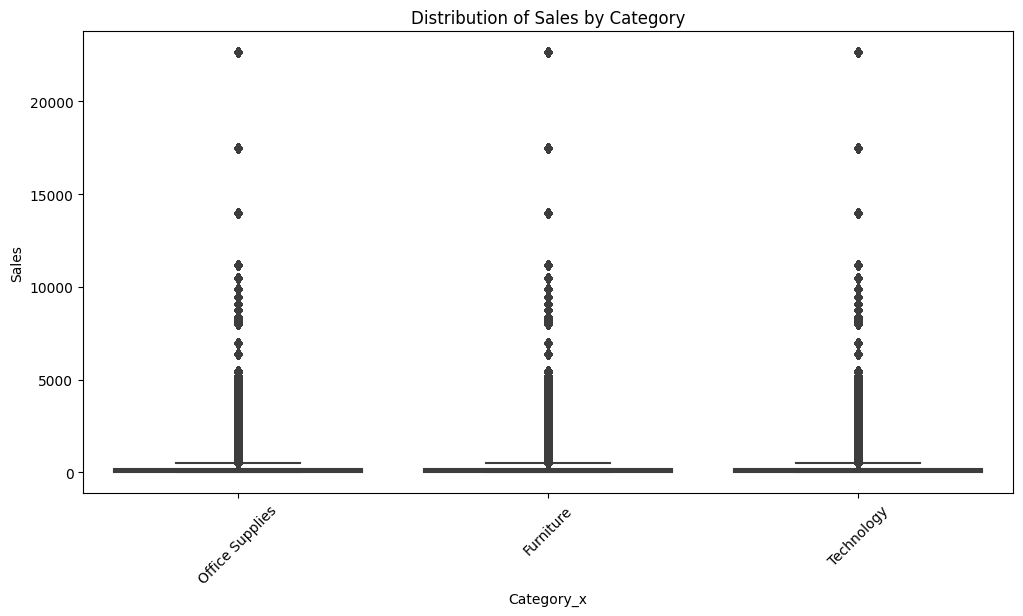

In [29]:
# Distribution of Sales and Profit by Category
plt.figure(figsize=(12, 6))
sns.boxplot(x='Category_x', y='Sales', data=merged_df)
plt.title('Distribution of Sales by Category')
plt.xticks(rotation=45)
plt.show()

A box plot was created to check the distribution between the sold categories and the sales beacuse to understand the variation of sales and profit for each category, it would be good to first understand the variation between sales and the category to get a clear idea on high performing segments.

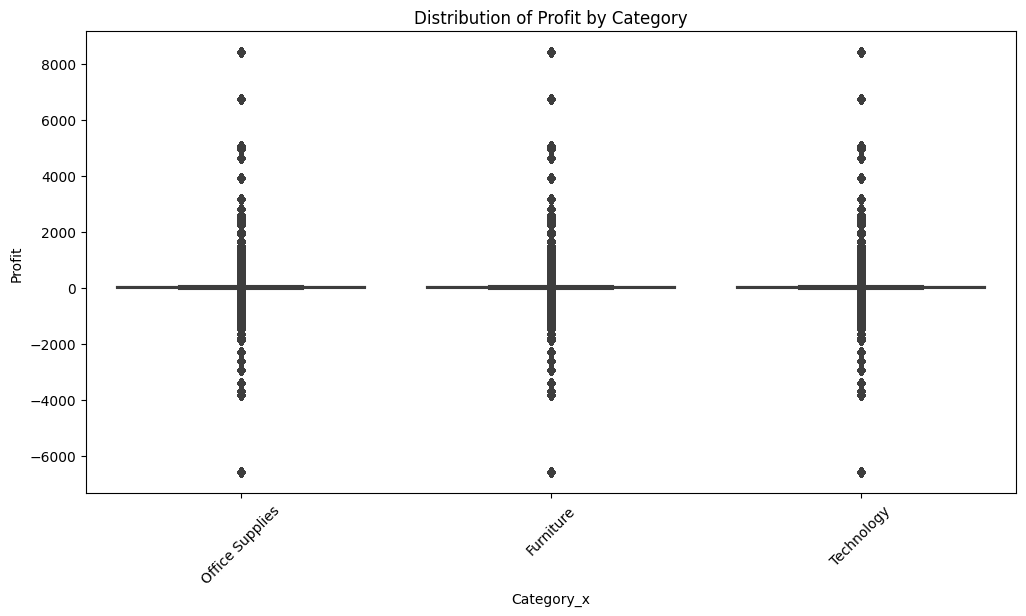

In [30]:
plt.figure(figsize=(12, 6))
sns.boxplot(x='Category_x', y='Profit', data=merged_df)
plt.title('Distribution of Profit by Category')
plt.xticks(rotation=45)
plt.show()

A box plot was drawn to have an idea on the generation of profit according to the sales of the each category.

In [1]:
# Sales trends over time (Order Date)
merged_df['Order_Date'] = pd.to_datetime(merged_df['Order_Date'])
merged_df.set_index('Order_Date', inplace=True)

NameError: ignored

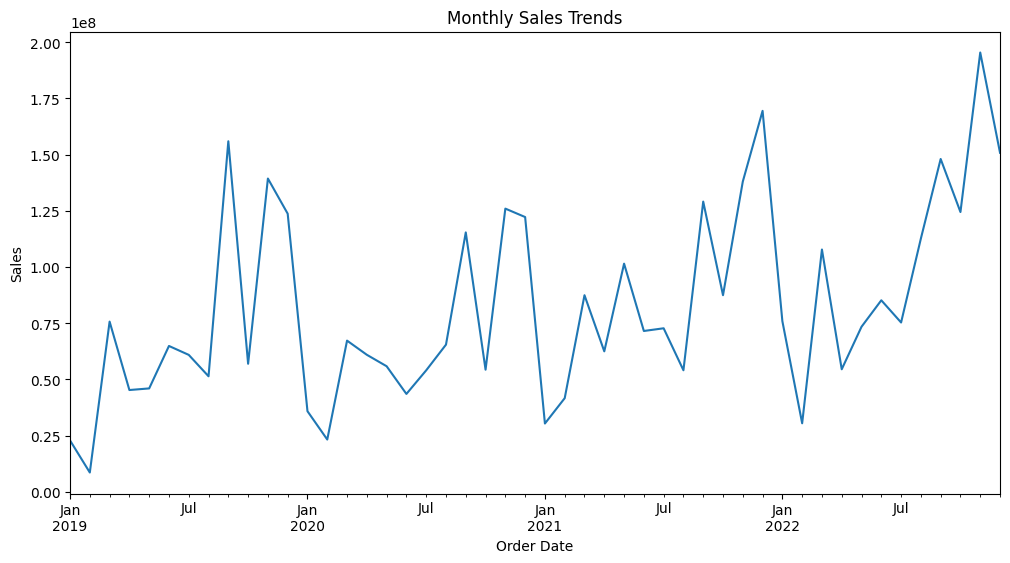

In [32]:
plt.figure(figsize=(12, 6))
merged_df['Sales'].resample('M').sum().plot()
plt.title('Monthly Sales Trends')
plt.xlabel('Order Date')
plt.ylabel('Sales')
plt.show()

The purpose of this is to visualize the monthly trend over time because time series analysis helps to identofy trends, patterns, seasonalities so this will be essential to forecast demands and for planning purposes.

In [ ]:
# Pairplot for selected numeric columns
sns.pairplot(merged_df[['Sales', 'Quantity', 'Discount', 'Profit']])
plt.title('Pairplot of Numeric Variables')
plt.show()

To check the pairwise relationsips between numerical variables. It also reveals if there are any correlation between variables.

In [ ]:
# Sales Target vs. Sales by Segment
segment_sales = merged_df.groupby('Segment_x')['Sales'].sum().reset_index()

fig = px.bar(segment_sales, x='Segment_x', y='Sales', title='Sales by Segment')
fig.show()

The purpose of this bar chart is to compare toal sales across different customer segments. This helps to identify which customer segments are driving revenue and it can be used to create marketing strategies for customer segments.

In [ ]:
# Correlation heatmap for selected numeric columns
correlation_matrix = merged_df[['Sales', 'Quantity', 'Discount', 'Profit']].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

This shows the correlation between numerical variables. This heatmap helps to identify strong positive and negative correlations.

In [ ]:
from statsmodels.tsa.arima_model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
import warnings
import numpy as np

In [ ]:
# Ignore warnings
warnings.filterwarnings("ignore")

In [ ]:
# Data Preparation
merged_df['Order Date'] = pd.to_datetime(merged_df['Order Date'])
merged_df.set_index('Order Date', inplace=True)